# DIPCOMA — Independent Testing: Variance- and Entropy-Based Ranking

**One-run Kaggle notebook.** This notebook adapts the uploaded training ranking notebook for the independent `dipcoma-test` dataset.

## Protocol
- Fit/freeze the two ranking methods using only `dipcoma-trainval` training-region patches.
- Apply the frozen band rankings to the six unseen test regions in `dipcoma-test`.
- Do not recompute ranking scores or choose bands using test data.
- Evaluate variance-ranking and entropy-ranking selections at identical Top-K budgets.
- Report region-wise and pooled test metrics. No labels are inferred from region names.

Attach both Kaggle datasets using **Add Input**:
- `krrishshandilya/dipcoma-trainval`
- `krrishshandilya/dipcoma-test`

Run all cells from top to bottom.

## 1. Configuration

`MAX_*_PATCHES_PER_REGION=None` processes all discovered patches. The default cap of 20 keeps a first run manageable; increase it for the final experiment. `AXIS_ORDER=None` detects the spectral axis as the smallest cube dimension (expected 13 bands); set it explicitly if the dataset format differs.

In [1]:
import os, re, json, time, math, warnings, platform, zipfile, hashlib
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
TOP_K = [3, 4, 5, 6, 8, 10, 12]
ENTROPY_BINS = 256
MAX_TRAIN_PATCHES_PER_REGION = 20
MAX_TEST_PATCHES_PER_REGION = 20
AXIS_ORDER = None                 # e.g. "BHW", "HWB"; None = smallest axis is spectral
EXPECTED_BANDS = 13
RECON_TRAIN_PIXELS_PER_PATCH = 5000  # sampled training pixels used to fit reconstruction regressors
MAX_RECON_TRAIN_PIXELS = 150000    # cap per fitted regressor for memory/runtime control
RUN_RECONSTRUCTION = True         # train-fitted regression; no wavelength metadata required
OUTPUT = Path("/kaggle/working/testing_ranking_outputs") if Path("/kaggle/working").exists() else Path("testing_ranking_outputs")
for d in ["tables","rankings","selected_bands","figures","reports","reduced_cubes","config"]:
    (OUTPUT/d).mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

## 2. Locate the two attached datasets

The notebook searches Kaggle's mounted input folders by dataset slug/name. If automatic discovery fails, set `TRAINVAL_ROOT` and `TEST_ROOT` explicitly.

In [2]:
def find_mount(token):
    root = Path("/kaggle/input")
    if not root.exists():
        return None
    token = token.lower().replace("-", "").replace("_", "")
    candidates = [p for p in root.iterdir() if p.is_dir()]
    for p in candidates:
        norm = p.name.lower().replace("-", "").replace("_", "")
        if token in norm:
            return p
    # search nested folders if Kaggle mount names are not descriptive
    for p in root.rglob("*"):
        if p.is_dir():
            norm = p.name.lower().replace("-", "").replace("_", "")
            if token in norm:
                return p
    return None

TRAINVAL_ROOT = find_mount("dipcoma-trainval")
TEST_ROOT = find_mount("dipcoma-test")
print("trainval:", TRAINVAL_ROOT)
print("test:", TEST_ROOT)
if TRAINVAL_ROOT is None or TEST_ROOT is None:
    raise FileNotFoundError(
        "Attach BOTH dipcoma-trainval and dipcoma-test with Kaggle Add Input, "
        "or set TRAINVAL_ROOT and TEST_ROOT to their mounted paths."
    )

trainval: /kaggle/input/datasets/krrishshandilya/dipcoma-trainval
test: /kaggle/input/datasets/krrishshandilya/dipcoma-test


## 3. Read and discover image patches

Supported formats: `.npy`, `.npz`, `.mat`, `.h5/.hdf5`, `.tif/.tiff`. Only 3-D numeric arrays with the expected spectral dimension are treated as cubes. Each file is processed independently; test regions are never used to fit rankings.

In [3]:
def load_numeric_array(path):
    path = Path(path)
    ext = path.suffix.lower()
    if ext == ".npy":
        return np.load(path, mmap_mode="r")
    if ext == ".npz":
        z = np.load(path, allow_pickle=False)
        keys = [k for k in z.files if np.asarray(z[k]).ndim == 3]
        if not keys: return None
        return z[max(keys, key=lambda k: np.asarray(z[k]).size)]
    if ext == ".mat":
        import scipy.io
        try:
            d = scipy.io.loadmat(path)
            arrs = [v for k,v in d.items() if not k.startswith("__") and isinstance(v,np.ndarray) and v.ndim==3]
            return max(arrs, key=lambda a:a.size) if arrs else None
        except NotImplementedError:
            import h5py
            with h5py.File(path,"r") as f:
                arrs=[]
                f.visititems(lambda n,o: arrs.append(o[()]) if isinstance(o,h5py.Dataset) and len(o.shape)==3 else None)
            return max(arrs,key=lambda a:a.size) if arrs else None
    if ext in (".h5",".hdf5"):
        import h5py
        with h5py.File(path,"r") as f:
            arrs=[]
            f.visititems(lambda n,o: arrs.append(o[()]) if isinstance(o,h5py.Dataset) and len(o.shape)==3 else None)
        return max(arrs,key=lambda a:a.size) if arrs else None
    if ext in (".tif",".tiff"):
        try:
            import rasterio
            with rasterio.open(path) as ds: return ds.read()
        except Exception:
            import tifffile
            return tifffile.imread(path)
    return None

def to_bhw(arr):
    a=np.asarray(arr)
    if a.ndim != 3: return None
    if AXIS_ORDER:
        if sorted(AXIS_ORDER) != sorted("BHW"): raise ValueError("AXIS_ORDER must be BHW, BHW permutation such as HWB/HBW")
        return np.transpose(a,[AXIS_ORDER.index(c) for c in "BHW"])
    # Prefer an axis exactly equal to EXPECTED_BANDS; otherwise use the smallest dimension.
    matches=[i for i,n in enumerate(a.shape) if n==EXPECTED_BANDS]
    axis=matches[0] if matches else int(np.argmin(a.shape))
    return np.moveaxis(a,axis,0)

VALID_EXTS={".npy",".npz",".mat",".h5",".hdf5",".tif",".tiff"}
def discover_cubes(root, split=None):
    root=Path(root)
    files=[]
    for p in root.rglob("*"):
        if not p.is_file() or p.suffix.lower() not in VALID_EXTS: continue
        relparts=[x.lower() for x in p.relative_to(root).parts]
        if split and split not in relparts: continue
        # Skip obvious labels/masks and metadata
        if re.search(r"(label|mask|ground.?truth|class|annotation|metadata)",p.stem,re.I): continue
        try:
            arr=load_numeric_array(p)
            cube=to_bhw(arr) if arr is not None else None
            if cube is not None and cube.shape[0] >= 3 and cube.shape[1] > 8 and cube.shape[2] > 8:
                files.append(p)
        except Exception as e:
            pass
    return sorted(files)

train_files=discover_cubes(TRAINVAL_ROOT, split="train")
test_files=discover_cubes(TEST_ROOT)
print("Discovered train cubes:",len(train_files))
print("Discovered test cubes:",len(test_files))
print("Example train:",[str(p.relative_to(TRAINVAL_ROOT)) for p in train_files[:5]])
print("Example test:",[str(p.relative_to(TEST_ROOT)) for p in test_files[:5]])
if not train_files or not test_files:
    raise RuntimeError("No 3-D cubes found. Inspect dataset structure and set AXIS_ORDER if required.")

Discovered train cubes: 957
Discovered test cubes: 396
Example train: ['dataset/train/amazon_manaus/20MRB_20250730_r0_c9.npy', 'dataset/train/amazon_manaus/20MRB_20250730_r1_c2.npy', 'dataset/train/amazon_manaus/20MRB_20250730_r1_c3.npy', 'dataset/train/amazon_manaus/20MRB_20250730_r1_c4.npy', 'dataset/train/amazon_manaus/20MRB_20250730_r2_c9.npy']
Example test: ['test/everest_region/45RVM_20250421_r0_c2.npy', 'test/everest_region/45RVM_20250421_r0_c3.npy', 'test/everest_region/45RVM_20250421_r0_c4.npy', 'test/everest_region/45RVM_20250421_r0_c6.npy', 'test/everest_region/45RVM_20250421_r1_c2.npy']


## 4. Region grouping and deterministic sampling

The region is taken from the first directory below the dataset root (or the split directory for trainval). Patches are sampled deterministically within each region. The notebook prints the resulting counts so the sampling protocol is auditable.

In [4]:
def region_name(path, root, train=False):
    parts=list(Path(path).relative_to(root).parts[:-1])
    # Remove generic container/split folders wherever they occur.
    ignored={"dataset","datasets","data","train","training","val","valid","validation","test"}
    meaningful=[p for p in parts if p.lower() not in ignored]
    return meaningful[0] if meaningful else "unknown_region"

def sample_by_region(files, root, cap, train=False):
    groups=defaultdict(list)
    for p in files: groups[region_name(p,root,train)].append(p)
    rng=np.random.default_rng(SEED)
    chosen={}
    for reg, paths in sorted(groups.items()):
        paths=sorted(paths)
        if cap is not None and len(paths)>cap:
            idx=sorted(rng.choice(len(paths),cap,replace=False).tolist())
            paths=[paths[i] for i in idx]
        chosen[reg]=paths
    return chosen

train_groups=sample_by_region(train_files,TRAINVAL_ROOT,MAX_TRAIN_PATCHES_PER_REGION,train=True)
test_groups=sample_by_region(test_files,TEST_ROOT,MAX_TEST_PATCHES_PER_REGION,train=False)
print("TRAIN PATCHES BY REGION:",{k:len(v) for k,v in train_groups.items()})
print("TEST PATCHES BY REGION:",{k:len(v) for k,v in test_groups.items()})

TRAIN PATCHES BY REGION: {'amazon_manaus': 20, 'atacama': 20, 'black_forest': 20, 'central_borneo': 20, 'central_valley': 20, 'delhi': 20, 'iceland_vatnajokull': 20, 'iowa': 20, 'lake_victoria': 20, 'maldives': 20, 'punjab': 20, 'sahara_algeria': 20, 'serengeti': 20, 'sundarbans': 20, 'swiss_alps': 20}
TEST PATCHES BY REGION: {'everest_region': 20, 'great_barrier_reef': 20, 'lagos': 20, 'northern_sweden': 20, 'po_valley': 20, 'rub_al_khali': 20}


## 5. Fit/freeze ranking scores on training regions only

Variance and Shannon entropy are calculated per spectral band on training patches. Scores are first computed per patch and then averaged across training patches, giving each patch equal weight. The ranking is global across training regions. Test arrays are not accessed in this section.

In [5]:
def cube_stats(path):
    arr=load_numeric_array(path)
    cube=to_bhw(arr).astype(np.float32,copy=False)
    if cube.shape[0] != EXPECTED_BANDS:
        raise ValueError(f"{path}: expected {EXPECTED_BANDS} bands, got {cube.shape}")
    mask=np.isfinite(cube).all(axis=0)
    if not mask.any(): raise ValueError(f"No valid pixels in {path}")
    x=cube[:,mask].astype(np.float64)
    # variance score on original numeric values
    var=np.var(x,axis=1,ddof=0)
    # common per-patch range across all bands; same bins for all bands within this patch
    lo=float(np.min(x)); hi=float(np.max(x))
    if hi<=lo:
        ent=np.zeros(cube.shape[0],dtype=float)
    else:
        edges=np.linspace(lo,hi,ENTROPY_BINS+1)
        ent=np.array([-(np.histogram(row,bins=edges)[0]/row.size *
                         np.log2(np.maximum(np.histogram(row,bins=edges)[0]/row.size,1e-300))).sum()
                      for row in x],dtype=float)
    return var,ent,cube,mask

train_records=[]
for region,paths in train_groups.items():
    for path in paths:
        try:
            v,e,_,_=cube_stats(path)
            train_records.append((region,str(path),v,e))
        except Exception as exc:
            print("SKIP TRAIN",path,repr(exc))
if not train_records: raise RuntimeError("No usable training cubes.")
BANDS=EXPECTED_BANDS
VAR_TRAIN=np.mean([r[2] for r in train_records],axis=0)
ENT_TRAIN=np.mean([r[3] for r in train_records],axis=0)
var_order=np.lexsort((np.arange(BANDS),-VAR_TRAIN))
ent_order=np.lexsort((np.arange(BANDS),-ENT_TRAIN))
print("Training patches used:",len(train_records))
print("Variance ranking (0-based):",var_order.tolist())
print("Entropy ranking (0-based):",ent_order.tolist())
pd.DataFrame({"band_0based":np.arange(BANDS),"variance_train":VAR_TRAIN,"variance_rank":np.argsort(np.argsort(-VAR_TRAIN))+1,
              "entropy_train":ENT_TRAIN,"entropy_rank":np.argsort(np.argsort(-ENT_TRAIN))+1}).to_csv(OUTPUT/"rankings"/"frozen_training_rankings.csv",index=False)

Training patches used: 300
Variance ranking (0-based): [8, 7, 6, 5, 11, 3, 4, 12, 2, 1, 0, 9, 10]
Entropy ranking (0-based): [8, 7, 6, 11, 5, 12, 4, 3, 2, 1, 9, 0, 10]


## 6. Freeze Top-K selections

The selected band indices are derived only from training scores. The same selections are reused unchanged for every test region and patch.

In [6]:
K_LIST=sorted(set(int(k) for k in TOP_K if 1<=int(k)<=BANDS))
if not K_LIST: raise ValueError("TOP_K contains no valid values.")
if max(K_LIST)>BANDS: raise ValueError(f"Top-K cannot exceed {BANDS} bands.")
SELECTIONS={
    "Variance":{k:var_order[:k].copy() for k in K_LIST},
    "Entropy":{k:ent_order[:k].copy() for k in K_LIST}
}
for method in SELECTIONS:
    for k,idx in SELECTIONS[method].items():
        pd.DataFrame({"rank":np.arange(1,k+1),"band_0based":idx,"band_1based":idx+1}).to_csv(
            OUTPUT/"selected_bands"/f"{method.lower()}_top{k}.csv",index=False)
print({m:{k:v.tolist() for k,v in d.items()} for m,d in SELECTIONS.items()})

{'Variance': {3: [8, 7, 6], 4: [8, 7, 6, 5], 5: [8, 7, 6, 5, 11], 6: [8, 7, 6, 5, 11, 3], 8: [8, 7, 6, 5, 11, 3, 4, 12], 10: [8, 7, 6, 5, 11, 3, 4, 12, 2, 1], 12: [8, 7, 6, 5, 11, 3, 4, 12, 2, 1, 0, 9]}, 'Entropy': {3: [8, 7, 6], 4: [8, 7, 6, 11], 5: [8, 7, 6, 11, 5], 6: [8, 7, 6, 11, 5, 12], 8: [8, 7, 6, 11, 5, 12, 4, 3], 10: [8, 7, 6, 11, 5, 12, 4, 3, 2, 1], 12: [8, 7, 6, 11, 5, 12, 4, 3, 2, 1, 9, 0]}}


In [7]:
# Fit one multivariate linear reconstruction model for each frozen ranking method and K.
# Crucially, only dipcoma-trainval/train patches are used here; test patches are never used to fit.
from sklearn.linear_model import LinearRegression

# Estimate a single fixed radiometric range from training patches only.
TRAIN_VALUE_MIN = np.inf
TRAIN_VALUE_MAX = -np.inf
for _region, _paths in sorted(train_groups.items()):
    for _path in _paths:
        try:
            _arr = load_numeric_array(_path)
            _cube = to_bhw(_arr).astype(np.float32, copy=False)
            _valid = np.isfinite(_cube).all(axis=0)
            if _valid.any():
                _vals = _cube[:, _valid]
                TRAIN_VALUE_MIN = min(TRAIN_VALUE_MIN, float(np.min(_vals)))
                TRAIN_VALUE_MAX = max(TRAIN_VALUE_MAX, float(np.max(_vals)))
        except Exception as _exc:
            print("SKIP TRAIN RANGE", _path, repr(_exc))
if not np.isfinite(TRAIN_VALUE_MIN) or not np.isfinite(TRAIN_VALUE_MAX):
    raise RuntimeError("Could not determine training-only radiometric range.")
TRAIN_DYNAMIC_RANGE = max(TRAIN_VALUE_MAX - TRAIN_VALUE_MIN, 1.0)

def fit_reconstruction_model(selected, seed=SEED):
    selected = np.asarray(selected, dtype=int)
    omitted = np.setdiff1d(np.arange(BANDS), selected)
    if len(omitted) == 0:
        return {"selected": selected, "omitted": omitted, "model": None,
                "train_pixels": 0, "train_fit_time_s": 0.0}
    rng = np.random.default_rng(seed)
    X_parts, Y_parts = [], []
    remaining = int(MAX_RECON_TRAIN_PIXELS)
    for region, paths in sorted(train_groups.items()):
        for path in paths:
            if remaining <= 0:
                break
            try:
                _, _, cube, mask = cube_stats(path)
                flat = cube.reshape(BANDS, -1).astype(np.float32, copy=False)
                valid_ids = np.flatnonzero(mask.reshape(-1))
                if not len(valid_ids):
                    continue
                n = min(RECON_TRAIN_PIXELS_PER_PATCH, len(valid_ids), remaining)
                ids = rng.choice(valid_ids, size=n, replace=False) if len(valid_ids) > n else valid_ids[:n]
                X_parts.append(flat[selected][:, ids].T)
                Y_parts.append(flat[omitted][:, ids].T)
                remaining -= len(ids)
            except Exception as exc:
                print("SKIP RECON TRAIN", path, repr(exc))
        if remaining <= 0:
            break
    if not X_parts:
        raise RuntimeError("No training pixels available for fitting reconstruction regression.")
    X_train = np.concatenate(X_parts, axis=0)
    Y_train = np.concatenate(Y_parts, axis=0)
    t0 = time.perf_counter()
    model = LinearRegression()
    model.fit(X_train, Y_train)
    elapsed = time.perf_counter() - t0
    return {"selected": selected, "omitted": omitted, "model": model,
            "train_pixels": int(len(X_train)), "train_fit_time_s": float(elapsed)}

RECON_MODELS = {}
recon_fit_rows = []
for method, by_k in SELECTIONS.items():
    for k, selected in by_k.items():
        key = (method, int(k))
        fitted = fit_reconstruction_model(selected, seed=SEED + int(k))
        RECON_MODELS[key] = fitted
        recon_fit_rows.append({
            "method": method, "K": int(k),
            "selected_bands_0based": json.dumps(np.asarray(selected, dtype=int).tolist()),
            "omitted_bands_0based": json.dumps(fitted["omitted"].tolist()),
            "training_pixels": fitted["train_pixels"],
            "regression_fit_time_s": fitted["train_fit_time_s"]
        })
pd.DataFrame(recon_fit_rows).to_csv(OUTPUT/"tables"/"reconstruction_regression_training.csv", index=False)
print("Fitted train-only reconstruction regressors:", len(RECON_MODELS))

Fitted train-only reconstruction regressors: 14


## 7. Test metrics and reconstruction

For each frozen ranking selection, a multivariate linear regression model is fitted on sampled **training** pixels to predict omitted bands from selected bands. The fitted regressor is then applied unchanged to each independent test patch.

Reported metrics:
- PSNR using a dynamic range calculated from training data only;
- SSIM on reconstructed omitted bands;
- SAM across full pixel spectra;
- MAE and MRE;
- selected-band redundancy;
- theoretical selected-band payload ratio and bpp estimate.

The test dataset is never used to fit regression coefficients, calculate the training dynamic range, rank bands, or select K. These are not measured JPEG2000 bitstream compression rates.

In [8]:
from skimage.metrics import structural_similarity

def reconstruct_from_selected(cube, selected, recon_model):
    selected = np.asarray(selected, dtype=int)
    omitted = np.setdiff1d(np.arange(BANDS), selected)
    recon = np.asarray(cube, dtype=np.float32).copy()
    if len(omitted):
        if recon_model is None:
            raise RuntimeError("Missing train-fitted reconstruction model.")
        flat = np.asarray(cube, dtype=np.float32).reshape(BANDS, -1)
        # Predict in chunks to avoid a large temporary matrix on 512x512 patches.
        predicted = np.empty((len(omitted), flat.shape[1]), dtype=np.float32)
        chunk = 100000
        for start in range(0, flat.shape[1], chunk):
            end = min(start + chunk, flat.shape[1])
            x_chunk = flat[selected, start:end].T
            predicted[:, start:end] = recon_model.predict(x_chunk).T
        recon.reshape(BANDS, -1)[omitted] = predicted
    # Preserve selected bands exactly; only omitted bands are reconstructed.
    recon[selected] = np.asarray(cube, dtype=np.float32)[selected]
    return recon

def test_patch_metrics(path, method, k, selected):
    arr = load_numeric_array(path)
    cube = to_bhw(arr).astype(np.float32, copy=False)
    if cube.shape[0] != BANDS:
        raise ValueError(f"Band count mismatch in {path}: {cube.shape[0]} vs {BANDS}")
    mask = np.isfinite(cube).all(axis=0)
    if not mask.any():
        raise ValueError(f"No valid pixels in {path}")
    # Invalid pixels are excluded from metric calculations.
    x = cube.astype(np.float64)
    selected = np.asarray(selected, dtype=int)
    key = (method, int(k))
    fitted = RECON_MODELS[key]
    recon = reconstruct_from_selected(cube, selected, fitted["model"]).astype(np.float64)
    valid = mask
    xv = x[:, valid]
    yv = recon[:, valid]
    err = xv - yv
    mse = float(np.mean(err ** 2))
    mae = float(np.mean(np.abs(err)))
    psnr = float("inf") if mse <= 0 else float(10.0 * np.log10((TRAIN_DYNAMIC_RANGE ** 2) / mse))

    # Spectral Angle Mapper, averaged over valid pixels.
    dot = np.sum(xv * yv, axis=0)
    denom = np.linalg.norm(xv, axis=0) * np.linalg.norm(yv, axis=0)
    ok = denom > 1e-12
    sam = float(np.degrees(np.arccos(np.clip(dot[ok] / denom[ok], -1.0, 1.0))).mean()) if ok.any() else np.nan

    # SSIM averaged over omitted bands, evaluated on a downsampled image for speed.
    omitted = np.setdiff1d(np.arange(BANDS), selected)
    ssim_vals = []
    step = 4
    for b in omitted:
        a = x[b, ::step, ::step]
        z = recon[b, ::step, ::step]
        data_range = float(max(TRAIN_DYNAMIC_RANGE, np.max(a) - np.min(a), 1.0))
        ssim_vals.append(float(structural_similarity(a, z, data_range=data_range, win_size=7)))
    ssim = float(np.mean(ssim_vals)) if ssim_vals else 1.0

    # Relative error only where the reference magnitude is not near zero.
    rel_eps = 1e-4 * TRAIN_DYNAMIC_RANGE
    mre_vals = []
    for b in omitted:
        band_ref = x[b, valid]
        band_err = np.abs(err[b])
        keep = np.abs(band_ref) > rel_eps
        if keep.any():
            mre_vals.append(float(np.mean(band_err[keep] / np.abs(band_ref[keep]))))
    mre = float(np.mean(mre_vals)) if mre_vals else np.nan

    selected_cube = cube[selected][:, valid].astype(np.float64)
    if len(selected) > 1:
        corr = np.corrcoef(selected_cube)
        tri = np.triu_indices(len(selected), 1)
        redundancy = float(np.nanmean(np.abs(corr[tri])))
    else:
        redundancy = np.nan

    bits = np.dtype(arr.dtype).itemsize * 8
    return {
        "method": method, "K": int(k), "region": region_name(path, TEST_ROOT),
        "patch": Path(path).name,
        "selected_0based": json.dumps(selected.tolist()),
        "n_valid_pixels": int(valid.sum()),
        "CR_theoretical": float(BANDS / len(selected)),
        "bpp_per_original_spectral_sample": float(len(selected) / BANDS),
        "bits_per_spatial_pixel": int(len(selected) * bits),
        "selected_redundancy": redundancy,
        "PSNR_dB": psnr, "SSIM": ssim, "SAM_deg": sam, "MAE": mae, "MRE": mre,
        "regression_fit_time_s": float(fitted["train_fit_time_s"]),
        "original_dtype": str(arr.dtype), "assumed_bits_per_sample": bits
    }

test_rows = []
errors = []
for region, paths in test_groups.items():
    for path in paths:
        for method in SELECTIONS:
            for k, selected in SELECTIONS[method].items():
                try:
                    test_rows.append(test_patch_metrics(path, method, k, selected))
                except Exception as exc:
                    errors.append({"path": str(path), "method": method, "K": k, "error": repr(exc)})
                    print("SKIP TEST", path, method, k, repr(exc))
TEST_RESULTS = pd.DataFrame(test_rows)
if TEST_RESULTS.empty:
    raise RuntimeError("No test results were produced; inspect test cube format and errors.")
TEST_RESULTS.to_csv(OUTPUT / "tables" / "test_patch_metrics.csv", index=False)
pd.DataFrame(errors).to_csv(OUTPUT / "reports" / "skipped_test_patches.csv", index=False)
print("Successful patch-method-K evaluations:", len(TEST_RESULTS))
print("Skipped evaluations:", len(errors))
print("Reconstruction metrics computed using train-fitted linear regression.")

Successful patch-method-K evaluations: 1680
Skipped evaluations: 0
Reconstruction metrics computed using train-fitted linear regression.


## 8. Region-wise and pooled test comparison

The pooled summary is the mean across patch-level rows. Region-wise summaries are also reported so a strong result in one region cannot hide poor performance elsewhere. Since CR and bpp are determined by K, they are theoretical storage ratios and will be identical for both ranking methods at the same K.

In [9]:
metric_cols=["selected_redundancy","PSNR_dB","SSIM","SAM_deg","MAE","MRE","CR_theoretical","bpp_per_original_spectral_sample"]
region_summary=TEST_RESULTS.groupby(["region","method","K"],dropna=False)[metric_cols].mean(numeric_only=True).reset_index()
pooled_summary=TEST_RESULTS.groupby(["method","K"],dropna=False)[metric_cols].agg(["mean","std","count"])
region_summary.to_csv(OUTPUT/"tables"/"region_wise_test_summary.csv",index=False)
pooled_summary.to_csv(OUTPUT/"tables"/"pooled_test_summary.csv")
print("POOLED TEST SUMMARY")
display(pooled_summary)
print("REGION-WISE TEST SUMMARY")
display(region_summary)

POOLED TEST SUMMARY


selected_redundancy                    PSNR_dB                   \
                           mean       std count       mean        std count   
method   K                                                                    
Entropy  3             0.961511  0.040697   120  34.185230   5.520655   120   
         4             0.812062  0.159907   120  38.826493   5.566707   120   
         5             0.844667  0.131190   120  40.197146   4.695944   120   
         6             0.797122  0.162836   120  40.375455   4.846981   120   
         8             0.782780  0.164172   120  42.630090   5.713740   120   
         10            0.741543  0.151352   120  45.904296   7.045649   120   
         12            0.718925  0.157651   120  71.517098  13.208078   120   
Variance 3             0.961511  0.040697   120  34.185230   5.520655   120   
         4             0.963194  0.035828   120  36.585314   5.783677   120   
         5             0.844667  0.131190   120  40.197148   4.695945   120   
         6             0.798140  0.154094   120  42.039772   5.299882   120   
         8             0.782780  0.164172   120  42.630089   5.713740   120   
         10            0.741543  0.151352   120  45.904295   7.045649   120   
         12            0.718925  0.157651   120  71.517097  13.208077   120   

                 SSIM                   SAM_deg  ...   MAE       MRE  \
                 mean       std count      mean  ... count      mean   
method   K                                       ...                   
Entropy  3   0.893179  0.093925   120  8.389237  ...   120  0.189975   
         4   0.951597  0.068377   120  5.352055  ...   120  0.120167   
         5   0.970739  0.026578   120  4.742484  ...   120  0.109875   
         6   0.968089  0.028468   120  4.607839  ...   120  0.115168   
         8   0.975260  0.023101   120  3.858204  ...   120  0.114633   
         10  0.968381  0.035714   120  2.913248  ...   120  0.124966   
         12  0.985451  0.038577   120  0.443770  ...   120  0.065287   
Variance 3   0.893179  0.093925   120  8.389237  ...   120  0.189975   
         4   0.937435  0.067122   120  7.082968  ...   120  0.171165   
         5   0.970739  0.026579   120  4.742484  ...   120  0.109875   
         6   0.979621  0.017868   120  4.126452  ...   120  0.097589   
         8   0.975260  0.023101   120  3.858204  ...   120  0.114633   
         10  0.968381  0.035714   120  2.913248  ...   120  0.124966   
         12  0.985451  0.038577   120  0.443770  ...   120  0.065287   

                            CR_theoretical             \
                  std count           mean  std count   
method   K                                              
Entropy  3   0.123325   120       4.333333  0.0   120   
         4   0.054808   120       3.250000  0.0   120   
         5   0.035693   120       2.600000  0.0   120   
         6   0.039658   120       2.166667  0.0   120   
         8   0.057154   120       1.625000  0.0   120   
         10  0.088774   120       1.300000  0.0   120   
         12  0.112731   120       1.083333  0.0   120   
Variance 3   0.123325   120       4.333333  0.0   120   
         4   0.146614   120       3.250000  0.0   120   
         5   0.035693   120       2.600000  0.0   120   
         6   0.041519   120       2.166667  0.0   120   
         8   0.057154   120       1.625000  0.0   120   
         10  0.088774   120       1.300000  0.0   120   
         12  0.112731   120       1.083333  0.0   120   

            bpp_per_original_spectral_sample             
                                        mean  std count  
method   K                                               
Entropy  3                          0.230769  0.0   120  
         4                          0.307692  0.0   120  
         5                          0.384615  0.0   120  
         6                          0.461538  0.0   120  
         8                          0.615385  0.0   120  
         

REGION-WISE TEST SUMMARY


,region,method,K,selected_redundancy,PSNR_dB,SSIM,SAM_deg,MAE,MRE,CR_theoretical,bpp_per_original_spectral_sample
0,everest_region,Entropy,3,0.985987,27.666091,0.821745,13.538757,732.215934,0.364687,4.333333,0.230769
1,everest_region,Entropy,4,0.789049,30.214172,0.837915,9.244940,639.511747,0.212164,3.250000,0.307692
2,everest_region,Entropy,5,0.828076,33.771916,0.929572,6.849877,373.989738,0.159527,2.600000,0.384615
3,everest_region,Entropy,6,0.771891,33.989436,0.923687,6.686439,356.104188,0.170993,2.166667,0.461538
4,everest_region,Entropy,8,0.808971,35.750901,0.936099,5.903366,248.214795,0.183439,1.625000,0.615385
...,...,...,...,...,...,...,...,...,...,...,...
79,rub_al_khali,Variance,5,0.943693,37.757741,0.985567,4.160530,202.821813,0.110073,2.600000,0.384615
80,rub_al_khali,Variance,6,0.930092,37.059329,0.982397,4.389142,219.208887,0.140022,2.166667,0.461538
81,rub_al_khali,Variance,8,0.936587,37.062183,0.974910,4.326471,170.721175,0.177256,1.625000,0.615385
82,rub_al_khali,Variance,10,0.750345,36.708881,0.957784,4.627559,123.508962,0.242236,1.300000,0.769231


## 9. Visualizations

These figures are generated from independent test results. The training rankings remain frozen.

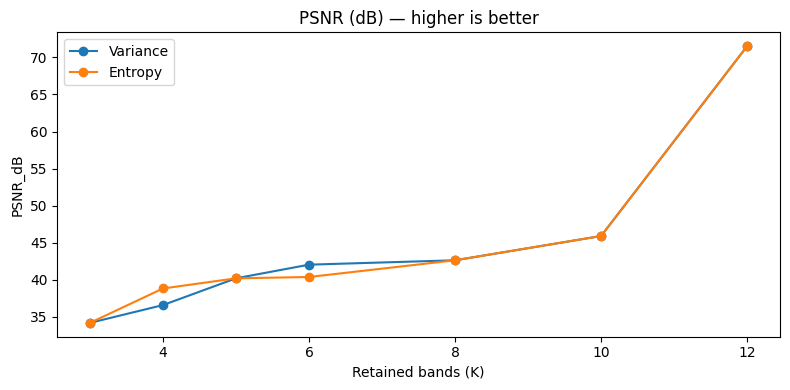

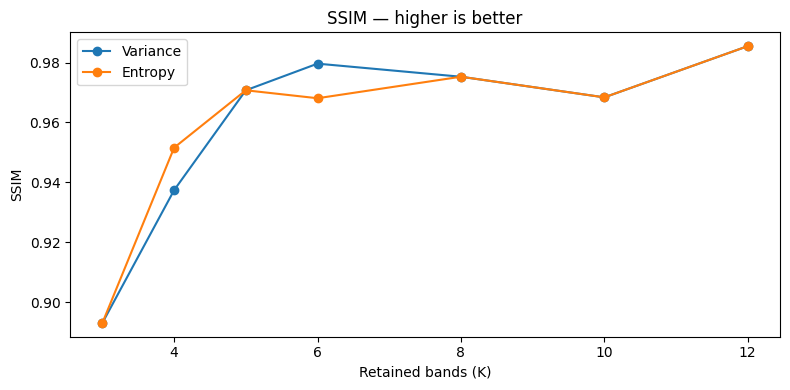

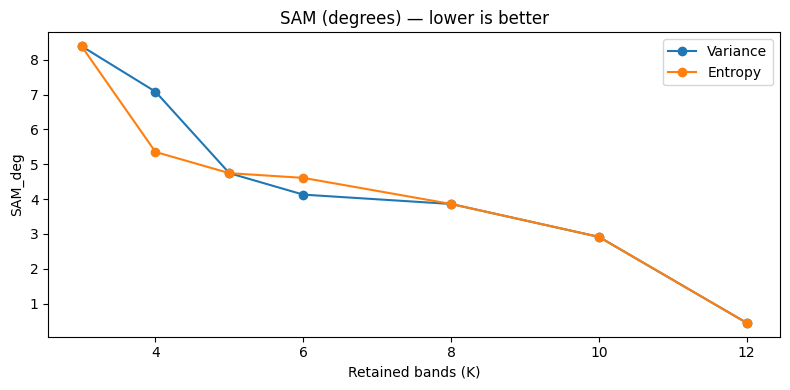

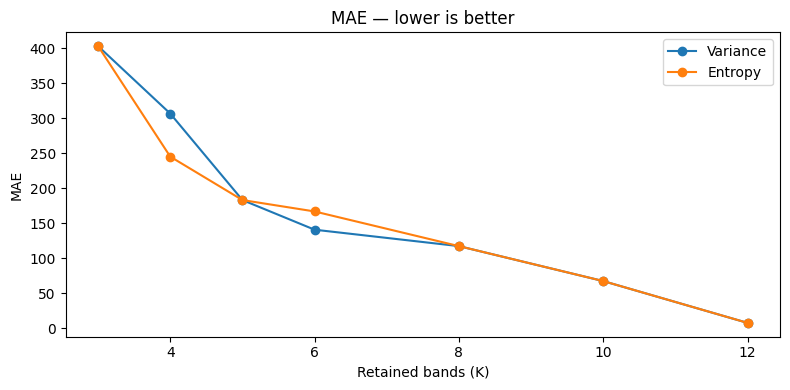

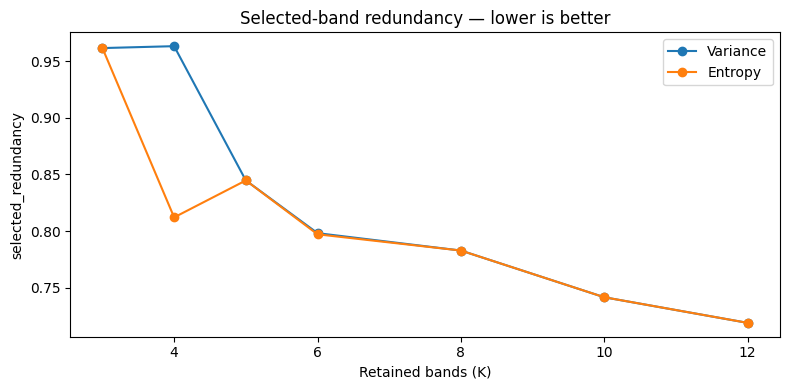

In [10]:
plot_metrics = [
    ("PSNR_dB", "PSNR (dB) — higher is better"),
    ("SSIM", "SSIM — higher is better"),
    ("SAM_deg", "SAM (degrees) — lower is better"),
    ("MAE", "MAE — lower is better"),
    ("selected_redundancy", "Selected-band redundancy — lower is better")
]
for metric, title in plot_metrics:
    fig, ax = plt.subplots(figsize=(8, 4))
    for method in SELECTIONS:
        d = pooled_summary.loc[method]
        if (metric, "mean") in d.columns:
            ax.plot(d.index, d[(metric, "mean")], marker="o", label=method)
    ax.set_xlabel("Retained bands (K)")
    ax.set_ylabel(metric)
    ax.set_title(title)
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend()
    else:
        ax.text(0.5, 0.5, "No finite values available", ha="center", va="center", transform=ax.transAxes)
    fig.tight_layout()
    fig.savefig(OUTPUT / "figures" / f"{metric}.png", dpi=160)
    plt.show()

## 10. Protocol checks and final report

The checks below record the source roots, selected bands, number of training/test patches and the fact that test data was not used to fit rankings.

In [11]:
summary={
 "protocol":"rankings fitted on train split only; frozen selections evaluated on independent test regions",
 "trainval_root":str(TRAINVAL_ROOT),"test_root":str(TEST_ROOT),
 "training_patches_used":len(train_records),
 "training_regions":{k:len(v) for k,v in train_groups.items()},
 "test_regions":{k:len(v) for k,v in test_groups.items()},
 "test_patch_count_successful":int(TEST_RESULTS[["region","patch"]].drop_duplicates().shape[0]),
 "test_evaluations":int(len(TEST_RESULTS)),
 "skipped_evaluations":int(len(errors)),
 "bands":BANDS,"top_k":K_LIST,"entropy_bins":ENTROPY_BINS,
 "frozen_selections":{m:{str(k):v.tolist() for k,v in d.items()} for m,d in SELECTIONS.items()},
 "reconstruction_method":"multivariate linear regression fitted on trainval/train only",
 "training_dynamic_range":float(TRAIN_DYNAMIC_RANGE),
 "reconstruction_metrics_available":True,
 "seed":SEED,"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__
}
(OUTPUT/"reports"/"run_summary.json").write_text(json.dumps(summary,indent=2))
(OUTPUT/"reports"/"README.txt").write_text(
 "DIPCOMA independent testing results for variance- and entropy-based band ranking.\n"
 "Rankings were fitted on dipcoma-trainval training patches only. Selected bands were frozen before evaluating dipcoma-test.\n"
 "CR/bpp are theoretical selected-band storage measures, not measured codec bitstreams.\n"
 "Reconstruction metrics are N/A unless real wavelength coordinates are supplied.\n"
)
zip_path=OUTPUT.parent/"testing_ranking_outputs.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for f in OUTPUT.rglob("*"):
        if f.is_file(): z.write(f,f.relative_to(OUTPUT.parent))
print(json.dumps(summary,indent=2))
print("Results folder:",OUTPUT.resolve())
print("ZIP:",zip_path.resolve())

{
  "protocol": "rankings fitted on train split only; frozen selections evaluated on independent test regions",
  "trainval_root": "/kaggle/input/datasets/krrishshandilya/dipcoma-trainval",
  "test_root": "/kaggle/input/datasets/krrishshandilya/dipcoma-test",
  "training_patches_used": 300,
  "training_regions": {
    "amazon_manaus": 20,
    "atacama": 20,
    "black_forest": 20,
    "central_borneo": 20,
    "central_valley": 20,
    "delhi": 20,
    "iceland_vatnajokull": 20,
    "iowa": 20,
    "lake_victoria": 20,
    "maldives": 20,
    "punjab": 20,
    "sahara_algeria": 20,
    "serengeti": 20,
    "sundarbans": 20,
    "swiss_alps": 20
  },
  "test_regions": {
    "everest_region": 20,
    "great_barrier_reef": 20,
    "lagos": 20,
    "northern_sweden": 20,
    "po_valley": 20,
    "rub_al_khali": 20
  },
  "test_patch_count_successful": 120,
  "test_evaluations": 1680,
  "skipped_evaluations": 0,
  "bands": 13,
  "top_k": [
    3,
    4,
    5,
    6,
    8,
    10,
    12
 


0. CHECKING NOTEBOOK STATE
methods=['Variance', 'Entropy'] | K list=[3, 4, 5, 6, 8, 10, 12] | bands=13 | fixed data range (train-only) = 28005

1. LEAKAGE AND CONSISTENCY CHECKS
OK: roots disjoint; no test patch is a training patch; every (method, K) has a train-fitted regressor with the right band set and shape.
Regressors were fitted on ~30 of 300 training patches, covering regions: ['amazon_manaus', 'atacama']
  [WARNING] Regression training pixels come from only 2 of 15 training regions (sampling stops at MAX_RECON_TRAIN_PIXELS). Not leakage, but the regressors are not representative; see the fix in the instructions (RECON_TRAIN_PIXELS_PER_PATCH).

2. TEST PATCHES
test regions: {'everest_region': 20, 'great_barrier_reef': 20, 'lagos': 20, 'northern_sweden': 20, 'po_valley': 20, 'rub_al_khali': 20} | total patches: 120
selected bands (frozen from TRAIN; 0-based | 1-based):
  Variance  K=3  [8, 7, 6] | [9, 8, 7]
  Variance  K=4  [8, 7, 6, 5] | [9, 8, 7, 6]
  Variance  K=5  [8, 7, 6,

Method,Reference K,Number of selected bands,Selected band indices (0-based),Selected band indices (1-based),Same band set as the other method?,BPP,MRE,SSIM,SAM (degrees),PSNR (dB),MAE,Compression ratio,BPP (actual .npz file),Test patches
Variance,3,3,"[8, 7, 6]","[9, 8, 7]",True,3.6923,0.18989,0.9203,8.3892,33.046,523.5,4.333,3.6937,120
Entropy,3,3,"[8, 7, 6]","[9, 8, 7]",True,3.6923,0.18989,0.9203,8.3892,33.046,523.5,4.333,3.6937,120
Variance,4,4,"[8, 7, 6, 5]","[9, 8, 7, 6]",False,4.9231,0.17108,0.9525,7.0830,34.988,442.7,3.250,4.9244,120
Entropy,4,4,"[8, 7, 6, 11]","[9, 8, 7, 12]",False,4.9231,0.12011,0.9631,5.3521,37.229,353.9,3.250,4.9244,120
Variance,5,5,"[8, 7, 6, 5, 11]","[9, 8, 7, 6, 12]",True,6.1538,0.10983,0.9759,4.7425,38.089,297.5,2.600,6.1552,120
Entropy,5,5,"[8, 7, 6, 11, 5]","[9, 8, 7, 12, 6]",True,6.1538,0.10983,0.9759,4.7425,38.089,297.5,2.600,6.1552,120
Variance,6,6,"[8, 7, 6, 5, 11, 3]","[9, 8, 7, 6, 12, 4]",False,7.3846,0.09754,0.9825,4.1265,39.351,261.5,2.167,7.3860,120
Entropy,6,6,"[8, 7, 6, 11, 5, 12]","[9, 8, 7, 12, 6, 13]",False,7.3846,0.11512,0.9737,4.6078,37.687,309.8,2.167,7.3860,120
Variance,8,8,"[8, 7, 6, 5, 11, 3, 4, 12]","[9, 8, 7, 6, 12, 4, 5, 13]",True,9.8462,0.11458,0.9792,3.8582,38.480,305.2,1.625,9.8476,120
Entropy,8,8,"[8, 7, 6, 11, 5, 12, 4, 3]","[9, 8, 7, 12, 6, 13, 5, 4]",True,9.8462,0.11458,0.9792,3.8582,38.480,305.2,1.625,9.8476,120



SAME EVALUATION, FULL-CUBE SCOPE (retained bands count as zero error / SSIM 1; matches the notebook's PSNR and MAE scope)


Method,Reference K,Number of selected bands,Selected band indices (0-based),Same band set as the other method?,BPP,MRE,SSIM,SAM (degrees),PSNR (dB),MAE,Compression ratio,BPP (actual .npz file),Test patches
Variance,3,3,"[8, 7, 6]",True,3.6923,0.14607,0.9387,8.3892,34.185,402.7,4.333,3.6937,120
Entropy,3,3,"[8, 7, 6]",True,3.6923,0.14607,0.9387,8.3892,34.185,402.7,4.333,3.6937,120
Variance,4,4,"[8, 7, 6, 5]",False,4.9231,0.11844,0.9671,7.0830,36.585,306.5,3.250,4.9244,120
Entropy,4,4,"[8, 7, 6, 11]",False,4.9231,0.08316,0.9745,5.3521,38.826,245,3.250,4.9244,120
Variance,5,5,"[8, 7, 6, 5, 11]",True,6.1538,0.06758,0.9851,4.7425,40.197,183.1,2.600,6.1552,120
Entropy,5,5,"[8, 7, 6, 11, 5]",True,6.1538,0.06758,0.9851,4.7425,40.197,183.1,2.600,6.1552,120
Variance,6,6,"[8, 7, 6, 5, 11, 3]",False,7.3846,0.05252,0.9906,4.1265,42.040,140.8,2.167,7.3860,120
Entropy,6,6,"[8, 7, 6, 11, 5, 12]",False,7.3846,0.06199,0.9859,4.6078,40.375,166.8,2.167,7.3860,120
Variance,8,8,"[8, 7, 6, 5, 11, 3, 4, 12]",True,9.8462,0.04407,0.9920,3.8582,42.630,117.4,1.625,9.8476,120
Entropy,8,8,"[8, 7, 6, 11, 5, 12, 4, 3]",True,9.8462,0.04407,0.9920,3.8582,42.630,117.4,1.625,9.8476,120



STANDARD DEVIATION ACROSS TEST PATCHES


method,K,BPP_std,MRE_omitted_std,SSIM_omitted_std,SAM_deg_std,PSNR_omitted_std,MAE_omitted_std,n_patches
Entropy,3,0.000000,0.123253,0.066125,3.247736,5.520655,334.396974,120
Entropy,4,0.000000,0.054798,0.048135,2.404011,5.566707,375.302070,120
Entropy,5,0.000000,0.035684,0.022591,1.456846,4.695944,216.827362,120
Entropy,6,0.000000,0.039647,0.024339,1.453702,4.846981,240.695418,120
Entropy,8,0.000000,0.057134,0.020856,1.557150,5.713740,248.199832,120
Entropy,10,0.000000,0.088738,0.035184,1.662658,7.045649,276.554457,120
Entropy,12,0.000000,0.112668,0.033907,0.827842,13.208078,207.461879,120
Variance,3,0.000000,0.123253,0.066125,3.247736,5.520655,334.396974,120
Variance,4,0.000000,0.146527,0.052484,3.156911,5.783677,353.520718,120
Variance,5,0.000000,0.035684,0.022591,1.456847,4.695945,216.827486,120



PAIRED DIFFERENCE Variance - Entropy (same patches). Where the band sets are identical the methods are tied BY CONSTRUCTION (differences are numerical noise).


K,metric,mean_Variance_minus_Entropy,std_error,share_patches_Variance_better,n_pairs,same_band_set
3,MRE_omitted,0.000000,0.000000,0.000000,120,True
3,SSIM_omitted,0.000000,0.000000,0.000000,120,True
3,SAM_deg,0.000000,0.000000,0.000000,120,True
3,PSNR_omitted,0.000000,0.000000,0.000000,120,True
3,MAE_omitted,0.000000,0.000000,0.000000,120,True
4,MRE_omitted,0.050966,0.009037,0.150000,120,False
4,SSIM_omitted,-0.010583,0.000978,0.183333,120,False
4,SAM_deg,1.730914,0.109008,0.066667,120,False
4,PSNR_omitted,-2.241179,0.211532,0.208333,120,False
4,MAE_omitted,88.743192,10.263539,0.233333,120,False



REGION-WISE MEANS (first 30 rows; full table in CSV)


region,method,K,BPP,BPP_actual_file,CR,MRE_omitted,MRE_fullcube,SSIM_omitted,SSIM_fullcube,SAM_deg,PSNR_omitted,PSNR_fullcube,MAE_omitted,MAE_fullcube
everest_region,Entropy,3,3.692308,3.693655,4.333333,0.364502,0.280386,0.858439,0.891107,13.538757,26.526658,27.666091,951.880714,732.215934
everest_region,Entropy,4,4.923077,4.924443,3.250000,0.212093,0.146834,0.887388,0.922038,9.244940,28.617164,30.214172,923.739191,639.511747
everest_region,Entropy,5,6.153846,6.155231,2.600000,0.159467,0.098134,0.940942,0.963657,6.849877,31.663382,33.771916,607.733324,373.989738
everest_region,Entropy,6,7.384615,7.386019,2.166667,0.170930,0.092039,0.935930,0.965501,6.686439,31.300983,33.989436,661.336349,356.104188
everest_region,Entropy,8,9.846154,9.847595,1.625000,0.183366,0.070525,0.944279,0.978569,5.903366,31.601168,35.750901,645.358466,248.214795
everest_region,Entropy,10,12.307692,12.309171,1.300000,0.243215,0.056126,0.912890,0.979898,5.417918,30.797041,37.165262,715.963863,165.222430
everest_region,Entropy,12,14.769231,14.770747,1.083333,0.302778,0.023291,0.923738,0.994134,2.161679,34.802061,45.941495,519.878249,39.990635
everest_region,Variance,3,3.692308,3.693655,4.333333,0.364502,0.280386,0.858439,0.891107,13.538757,26.526658,27.666091,951.880714,732.215934
everest_region,Variance,4,4.923077,4.924443,3.250000,0.386359,0.267479,0.869875,0.909914,12.498502,26.717681,28.314689,954.708770,660.952225
everest_region,Variance,5,6.153846,6.155231,2.600000,0.159468,0.098134,0.940942,0.963657,6.849880,31.663379,33.771913,607.733691,373.989964



K values where both methods selected the SAME bands (identical results): [3, 5, 8, 10, 12] | K values where the sets differ: [4, 6]

CONSISTENCY with notebook TEST_RESULTS (PSNR/SAM/MAE share definitions; MRE, SSIM, BPP intentionally differ): {'rows_compared': 1680, 'max_abs_diff_PSNR_dB': 0.0, 'max_abs_diff_SAM_deg': 0.0, 'max_abs_diff_MAE': 0.0}

5. FIGURES


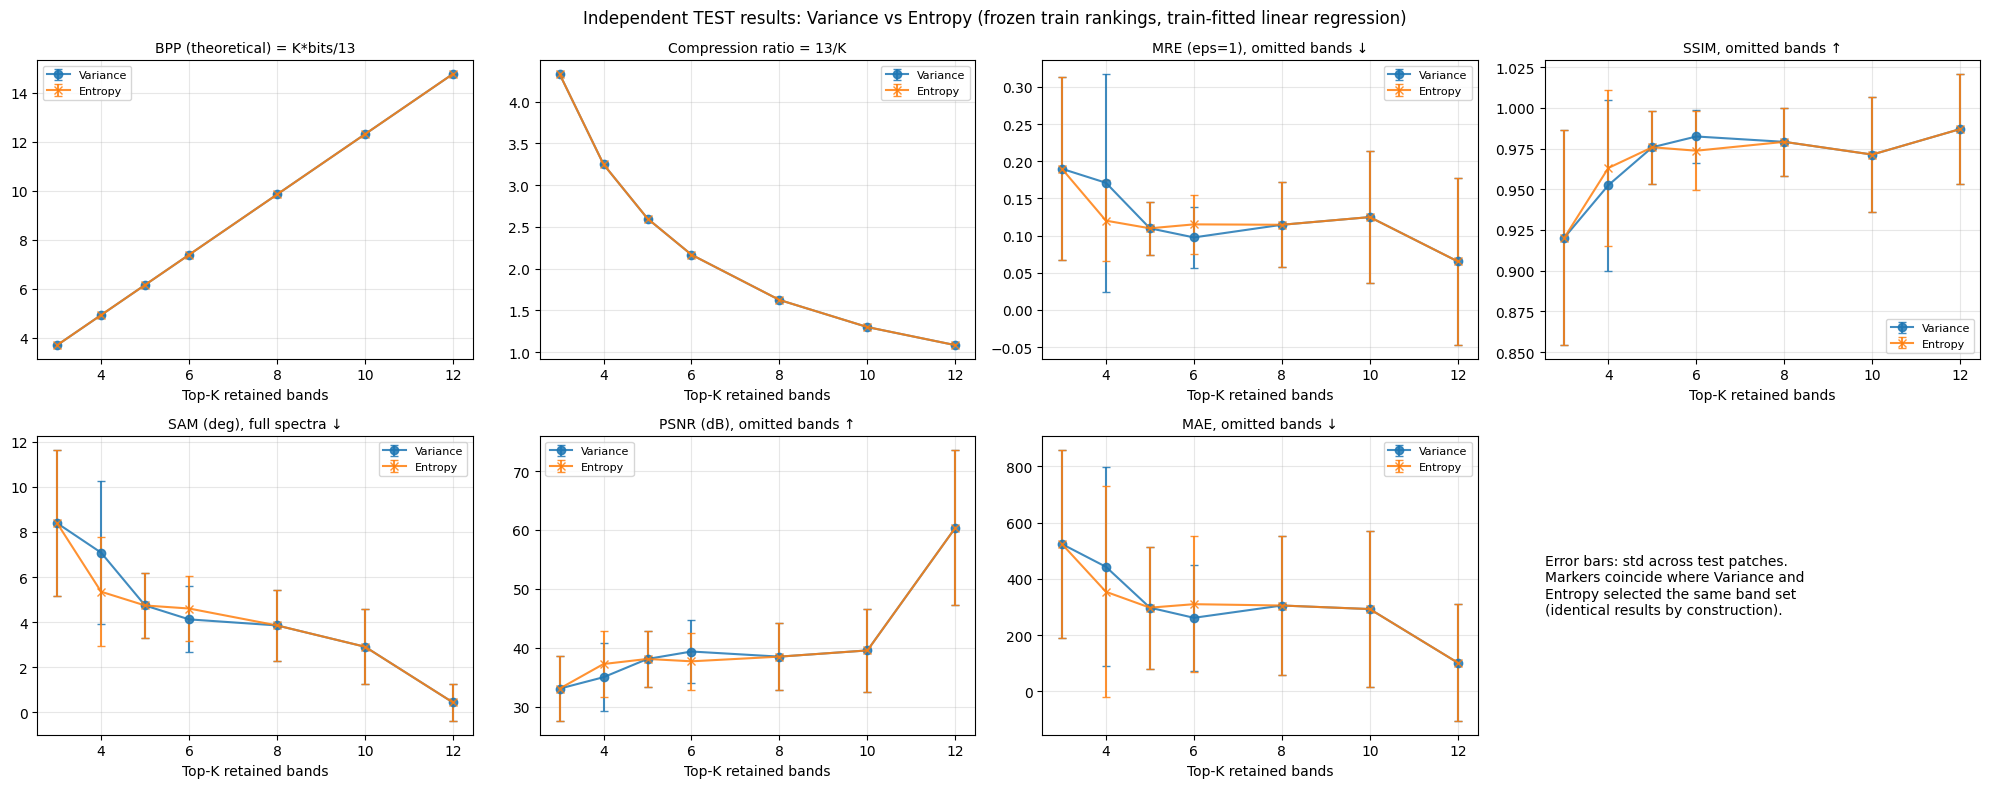

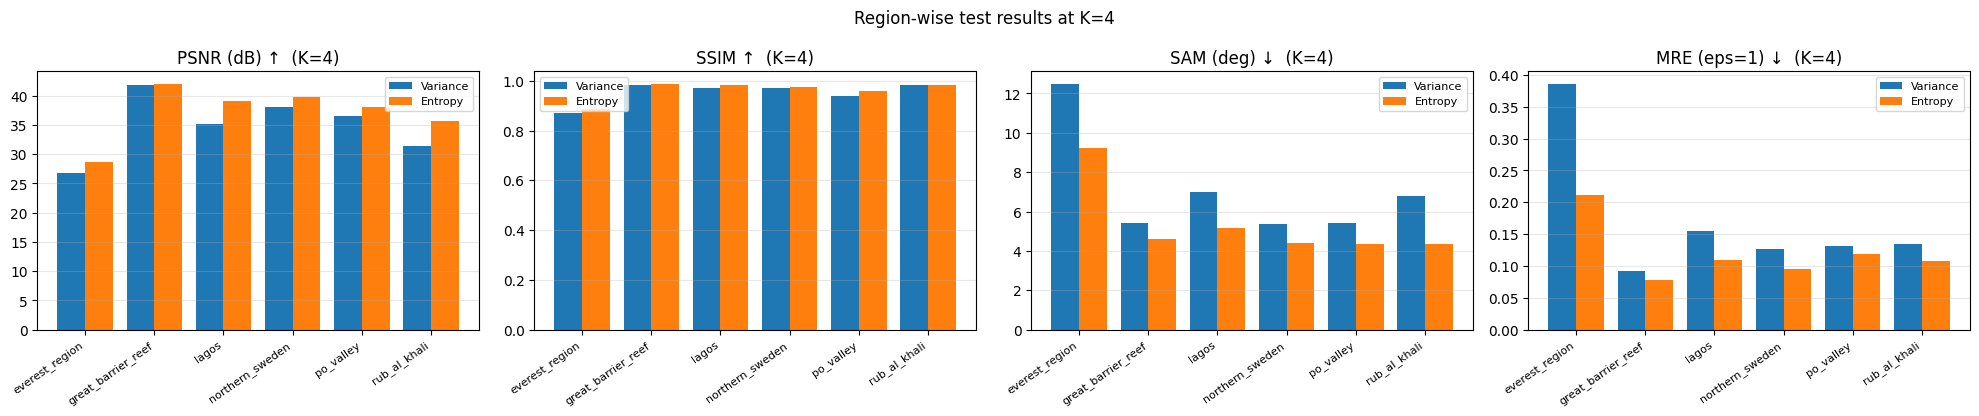


6. SAVING
Integrity: frozen selections unchanged; nothing was refitted, re-ranked or tuned on test data.
Saved to /kaggle/working :
  notes_test_patch_metrics.csv
  notes_test_final_table.csv
  notes_test_fullcube_table.csv
  notes_test_std_across_patches.csv
  notes_test_region_summary.csv
  notes_test_paired_variance_minus_entropy.csv
  notes_test_skipped_patches.csv
  notes_test_results.json
  figures/notes_test_metrics_vs_K.png
  figures/notes_test_region_bars.png

WARNINGS:
  - Regression training pixels come from only 2 of 15 training regions (sampling stops at MAX_RECON_TRAIN_PIXELS). Not leakage, but the regressors are not representative; see the fix in the instructions (RECON_TRAIN_PIXELS_PER_PATCH).

Done in 732s


In [12]:
# =====================================================================================
#  NOTES-BASED INDEPENDENT TEST EVALUATION — Variance vs Entropy Top-K band ranking
#  Paste as a NEW cell at the very END of the notebook (after the "Protocol checks" cell).
#  Re-uses (does not refit): SELECTIONS, RECON_MODELS, TRAIN_DYNAMIC_RANGE, test_groups, test_files,
#  load_numeric_array, to_bhw, region_name, reconstruct_from_selected, BANDS, K_LIST, TEST_ROOT, TRAINVAL_ROOT
#  Adds the metrics from the handwritten notes: BPP, MRE (eps = 1), SSIM, SAM  (+ PSNR, MAE, CR)
# =====================================================================================
import io, json, time, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity          # same SSIM library as the notebook

NOTES_CFG = dict(
    use_all_test_patches=False,   # False: the SAME capped patches as the notebook (test_groups); True: every discovered test patch
    bits_override=None,           # None: bits/sample = dtype of each .npy file;  e.g. 16 = treat data as 16-bit DN
    mre_eps=1.0,                  # epsilon from your notes (raw data units)
    ssim_win=7,                   # uniform 7x7 window (same as the notebook)
    k_for_region_plot=None,       # None -> first K whose Variance/Entropy band sets differ
)
_T0 = time.time(); _WARN = []
def _warn(m): _WARN.append(m); print("  [WARNING]", m)
def _hdr(t): print("\n" + "=" * 100 + f"\n{t}\n" + "=" * 100)

# ------------------------------------ 0. state checks ------------------------------------
_hdr("0. CHECKING NOTEBOOK STATE")
_need = ["SELECTIONS", "RECON_MODELS", "TRAIN_DYNAMIC_RANGE", "test_groups", "test_files", "load_numeric_array", "to_bhw", "region_name",
         "reconstruct_from_selected", "BANDS", "K_LIST", "TEST_ROOT", "TRAINVAL_ROOT", "train_groups", "sample_by_region", "SEED"]
_miss = [n for n in _need if n not in globals()]
if _miss:
    raise RuntimeError(f"Missing notebook objects {_miss}. Run the notebook top-to-bottom first (sections 1-7). Nothing was invented.")
_METHODS = list(SELECTIONS.keys())
NOTES_OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
(NOTES_OUT / "figures").mkdir(exist_ok=True, parents=True)
L_FIXED = float(TRAIN_DYNAMIC_RANGE)       # fixed radiometric range from TRAIN data only -> PSNR max and SSIM data_range for ALL methods/patches
print(f"methods={_METHODS} | K list={list(K_LIST)} | bands={BANDS} | fixed data range (train-only) = {L_FIXED:g}")
_SEL_HASH0 = json.dumps({m: {str(k): np.asarray(v).tolist() for k, v in d.items()} for m, d in SELECTIONS.items()}, sort_keys=True)

# ------------------------------------ 1. leakage / consistency checks ------------------------------------
_hdr("1. LEAKAGE AND CONSISTENCY CHECKS")
def _under(p, root):
    try: Path(p).resolve().relative_to(Path(root).resolve()); return True
    except ValueError: return False
assert not _under(TEST_ROOT, TRAINVAL_ROOT) and not _under(TRAINVAL_ROOT, TEST_ROOT) and Path(TEST_ROOT).resolve() != Path(TRAINVAL_ROOT).resolve(), "test and trainval roots overlap"
_train_paths = {str(Path(p).resolve()) for ps in train_groups.values() for p in ps}
_tp = [Path(p) for ps in test_groups.values() for p in ps]
assert not (_train_paths & {str(p.resolve()) for p in _tp}), "a test patch is also a training patch"
assert all(_under(p, TEST_ROOT) for p in _tp), "a test patch lies outside TEST_ROOT"
for m in _METHODS:
    for k, sel in SELECTIONS[m].items():
        sel = np.asarray(sel, int)
        assert len(sel) == k and len(set(sel.tolist())) == k and sel.min() >= 0 and sel.max() < BANDS, f"invalid selection {m} K={k}"
        fit = RECON_MODELS.get((m, int(k)))
        assert fit is not None, f"no train-fitted regressor for {m} K={k}"
        assert np.array_equal(np.asarray(fit["selected"], int), sel), f"regressor {m} K={k} was fitted for different bands"
        if len(sel) < BANDS:
            assert fit["model"].coef_.shape == (BANDS - k, k), f"regressor {m} K={k}: unexpected coefficient shape {fit['model'].coef_.shape}"
print("OK: roots disjoint; no test patch is a training patch; every (method, K) has a train-fitted regressor with the right band set and shape.")
# which training patches fed the regressors? (the notebook stops sampling once MAX_RECON_TRAIN_PIXELS is reached)
if "RECON_TRAIN_PIXELS_PER_PATCH" in globals():
    _n_used = int(math.ceil(max(f["train_pixels"] for f in RECON_MODELS.values()) / RECON_TRAIN_PIXELS_PER_PATCH)); _cum, _cov = 0, []
    for reg, ps in sorted(train_groups.items()):
        if _cum < _n_used: _cov.append(reg)
        _cum += len(ps)
    print(f"Regressors were fitted on ~{_n_used} of {sum(len(v) for v in train_groups.values())} training patches, covering regions: {_cov}")
    if len(_cov) < len(train_groups):
        _warn(f"Regression training pixels come from only {len(_cov)} of {len(train_groups)} training regions (sampling stops at MAX_RECON_TRAIN_PIXELS). "
              f"Not leakage, but the regressors are not representative; see the fix in the instructions (RECON_TRAIN_PIXELS_PER_PATCH).")

# ------------------------------------ 2. test patch list ------------------------------------
_hdr("2. TEST PATCHES")
GROUPS = sample_by_region(test_files, TEST_ROOT, None) if NOTES_CFG["use_all_test_patches"] else test_groups
print("test regions:", {k: len(v) for k, v in GROUPS.items()}, "| total patches:", sum(len(v) for v in GROUPS.values()))
print("selected bands (frozen from TRAIN; 0-based | 1-based):")
for m in _METHODS:
    for k in K_LIST:
        s = np.asarray(SELECTIONS[m][k], int); print(f"  {m:<9} K={k:<2} {s.tolist()} | {(s + 1).tolist()}")

# ------------------------------------ 3. per-patch evaluation ------------------------------------
def _eval_patch(path):
    arr = load_numeric_array(path)
    if arr is None: raise ValueError("no 3-D numeric array")
    c0 = to_bhw(arr)
    if c0 is None or c0.ndim != 3 or c0.shape[0] != BANDS: raise ValueError(f"expected {BANDS} spectral bands, got shape {None if c0 is None else c0.shape}")
    _, H, W = c0.shape
    cube = np.asarray(c0, dtype=np.float32)
    fin = np.isfinite(cube); valid = fin.all(axis=0); nv = int(valid.sum())
    if nv == 0: raise ValueError("no valid pixels (all NaN/Inf)")
    clean = np.where(fin, cube, 0.0).astype(np.float32)
    x = clean.astype(np.float64); xv = x[:, valid]; nx = np.linalg.norm(xv, axis=0)
    bits = int(NOTES_CFG["bits_override"] or np.dtype(arr.dtype).itemsize * 8)
    native = np.asarray(c0)                                              # native dtype, (B,H,W)
    pad = (NOTES_CFG["ssim_win"] - 1) // 2; win = NOTES_CFG["ssim_win"]
    vm = valid[pad:-pad, pad:-pad] if min(H, W) >= win else None
    rows = []
    for m in _METHODS:
        for k in K_LIST:
            sel = np.asarray(SELECTIONS[m][k], int); om = np.setdiff1d(np.arange(BANDS), sel)
            rec = reconstruct_from_selected(clean, sel, RECON_MODELS[(m, int(k))]["model"]).astype(np.float64)   # notebook's reconstruction (train-fitted regression)
            yv = rec[:, valid]
            if not np.isfinite(yv).all(): raise ValueError(f"non-finite reconstruction for {m} K={k}")
            assert np.array_equal(rec[sel], x[sel]), "selected bands must be reproduced exactly"
            err = xv - yv; ae = np.abs(err)
            mre = ae / (np.abs(xv) + NOTES_CFG["mre_eps"])               # notes: |X - Xhat| / (|X| + eps), eps = 1
            dot = (xv * yv).sum(0); den = nx * np.linalg.norm(yv, axis=0); ok = den > 1e-12     # zero-norm spectra excluded and counted
            sam = float(np.degrees(np.arccos(np.clip(dot[ok] / den[ok], -1.0, 1.0))).mean()) if ok.any() else np.nan
            ss = []
            if vm is not None:
                for b in om:                                              # 2-D SSIM per reconstructed band, FIXED data range, full resolution
                    S = structural_similarity(x[b], rec[b], data_range=L_FIXED, win_size=win, use_sample_covariance=False, full=True)[1]
                    sv = S[pad:-pad, pad:-pad][vm]; ss.append(float(sv.mean()) if sv.size else np.nan)
            ssim_om = float(np.nanmean(ss)) if ss and np.isfinite(ss).any() else np.nan
            ssim_full = float((np.nansum(ss) + (BANDS - len(om))) / BANDS) if np.isfinite(ssim_om) else np.nan   # retained bands are exact -> SSIM = 1
            mse_f, mse_o = float((err ** 2).mean()), float((err[om] ** 2).mean())
            psnr = lambda mse: float("inf") if mse <= 0 else float(10 * math.log10(L_FIXED ** 2 / mse))
            buf = io.BytesIO(); np.savez(buf, cube=native[sel], selected_band_indices_0based=sel)           # ACTUAL stored representation (uncompressed .npz in memory)
            comp_bits = H * W * k * bits                                                                    # THEORETICAL payload
            rows.append(dict(
                method=m, K=int(k), region=region_name(path, TEST_ROOT), patch=Path(path).name, H=H, W=W, n_valid_pixels=nv,
                selected_0based=json.dumps(sel.tolist()), selected_1based=json.dumps((sel + 1).tolist()),
                bits_per_sample=bits, dtype=str(arr.dtype),
                BPP=comp_bits / (H * W * BANDS), BPP_actual_file=8 * buf.getbuffer().nbytes / (H * W * BANDS),
                CR=(H * W * BANDS * bits) / comp_bits,
                MRE_omitted=float(mre[om].mean()), MRE_fullcube=float(mre.mean()),
                SSIM_omitted=ssim_om, SSIM_fullcube=ssim_full,
                SAM_deg=sam, SAM_zero_norm_pixels=int((~ok).sum()),
                PSNR_omitted=psnr(mse_o), PSNR_fullcube=psnr(mse_f),
                MAE_omitted=float(ae[om].mean()), MAE_fullcube=float(ae.mean())))
    return rows

_hdr("3. EVALUATING TEST PATCHES (no refitting; frozen selections + train-fitted regressors)")
ROWS, SKIPPED = [], []; all_p = [(r, p) for r, ps in GROUPS.items() for p in ps]; t0 = time.time()
for i, (reg, p) in enumerate(all_p, 1):
    try: ROWS += _eval_patch(p)
    except Exception as e:
        SKIPPED.append(dict(region=reg, patch=str(p), error=f"{type(e).__name__}: {e}")); print(f"  SKIP {reg}/{Path(p).name}: {type(e).__name__}: {e}")
    if i % 10 == 0 or i == len(all_p):
        el = time.time() - t0; print(f"  {i}/{len(all_p)} patches | {el:.0f}s elapsed | ETA {el / i * (len(all_p) - i):.0f}s")
NOTES_RESULTS = pd.DataFrame(ROWS)
if NOTES_RESULTS.empty: raise RuntimeError("No test results were produced. See the skipped-patch messages above.")
pd.DataFrame(SKIPPED, columns=["region", "patch", "error"]).to_csv(NOTES_OUT / "notes_test_skipped_patches.csv", index=False)
NOTES_RESULTS.to_csv(NOTES_OUT / "notes_test_patch_metrics.csv", index=False)
n_ok = NOTES_RESULTS[["region", "patch"]].drop_duplicates().shape[0]
print(f"\nPatches evaluated: {n_ok} | skipped: {len(SKIPPED)} | regions: {sorted(NOTES_RESULTS.region.unique())} | rows: {len(NOTES_RESULTS)}")
for s in SKIPPED: print("  skipped:", s["patch"], "->", s["error"])
_num = NOTES_RESULTS.select_dtypes("number")
assert not np.isnan(NOTES_RESULTS[["BPP", "CR", "MRE_omitted", "MAE_omitted"]].values).any(), "NaN in a core metric"
print("bit depth used for theoretical BPP:", sorted(NOTES_RESULTS.bits_per_sample.unique()), "| dtypes:", sorted(NOTES_RESULTS.dtype.unique()))
if NOTES_RESULTS.dtype.str.contains("float").any() and not NOTES_CFG["bits_override"]:
    _warn("Test files are floating point, so theoretical BPP assumes 32 (or 64) bits/sample. If the data is really 12/16-bit DN, set NOTES_CFG['bits_override'] (e.g. 16).")
_ninf = int(np.isinf(NOTES_RESULTS[["PSNR_omitted", "PSNR_fullcube"]].values).sum())
if _ninf: _warn(f"{_ninf} PSNR values are +inf (zero error); they are excluded from PSNR means.")

# ------------------------------------ 4. tables ------------------------------------
_hdr("4. RESULTS")
MET = ["BPP", "BPP_actual_file", "CR", "MRE_omitted", "MRE_fullcube", "SSIM_omitted", "SSIM_fullcube", "SAM_deg", "PSNR_omitted", "PSNR_fullcube", "MAE_omitted", "MAE_fullcube"]
R = NOTES_RESULTS.replace([np.inf, -np.inf], np.nan)
MEAN = R.groupby(["method", "K"])[MET].mean(); STD = R.groupby(["method", "K"])[MET].std(); NP = R.groupby(["method", "K"]).size()
SEL0 = {(m, k): np.asarray(SELECTIONS[m][k], int) for m in _METHODS for k in K_LIST}
def _same(m, k): return any(set(SEL0[(m, k)].tolist()) == set(SEL0[(o, k)].tolist()) for o in _METHODS if o != m)

def _final(scope):
    rows = []
    for k in K_LIST:
        for m in _METHODS:
            r = MEAN.loc[(m, k)]; s = SEL0[(m, k)]
            rows.append({"Method": m, "Reference K": k, "Number of selected bands": len(s), "Selected band indices (0-based)": s.tolist(),
                         "Selected band indices (1-based)": (s + 1).tolist(), "Same band set as the other method?": _same(m, k),
                         "BPP": r.BPP, "MRE": r[f"MRE_{scope}"], "SSIM": r[f"SSIM_{scope}"], "SAM (degrees)": r.SAM_deg,
                         "PSNR (dB)": r[f"PSNR_{scope}"], "MAE": r[f"MAE_{scope}"], "Compression ratio": r.CR, "BPP (actual .npz file)": r.BPP_actual_file,
                         "Test patches": int(NP.loc[(m, k)])})
    return pd.DataFrame(rows)
FINAL_OMITTED, FINAL_FULL = _final("omitted"), _final("fullcube")
STD_TABLE = STD[["BPP", "MRE_omitted", "SSIM_omitted", "SAM_deg", "PSNR_omitted", "MAE_omitted"]].add_suffix("_std").join(NP.rename("n_patches")).reset_index()
REGION = R.groupby(["region", "method", "K"])[MET].mean().reset_index()

# paired Variance - Entropy comparison per K (same patches)
_pm = ["MRE_omitted", "SSIM_omitted", "SAM_deg", "PSNR_omitted", "MAE_omitted"]; _better_low = {"MRE_omitted": True, "SSIM_omitted": False, "SAM_deg": True, "PSNR_omitted": False, "MAE_omitted": True}
PAIRED = []
if len(_METHODS) == 2 and set(_METHODS) == {"Variance", "Entropy"}:
    for k in K_LIST:
        a = R[(R.method == "Variance") & (R.K == k)].set_index(["region", "patch"]); b = R[(R.method == "Entropy") & (R.K == k)].set_index(["region", "patch"])
        idx = a.index.intersection(b.index)
        for mt in _pm:
            d = (a.loc[idx, mt] - b.loc[idx, mt]).dropna(); n = len(d)
            var_better = float(((d < 0) if _better_low[mt] else (d > 0)).mean()) if n else np.nan
            PAIRED.append(dict(K=k, metric=mt, mean_Variance_minus_Entropy=float(d.mean()) if n else np.nan, std_error=float(d.std(ddof=1) / math.sqrt(n)) if n > 1 else np.nan,
                               share_patches_Variance_better=var_better, n_pairs=n, same_band_set=_same("Variance", k)))
PAIRED = pd.DataFrame(PAIRED)

try: from IPython.display import display as _ipy_display
except Exception: _ipy_display = print
def _disp(df, fmt=None, hide=None):
    """Show a DataFrame (styled if possible, plain otherwise)."""
    d = df.drop(columns=hide) if hide else df
    try: _ipy_display(d.style.format(fmt or {}, na_rep="N/A").hide(axis="index"))
    except Exception: _ipy_display(d)
_f = {"BPP": "{:.4f}", "MRE": "{:.5f}", "SSIM": "{:.4f}", "SAM (degrees)": "{:.4f}", "PSNR (dB)": "{:.3f}", "MAE": "{:.4g}", "Compression ratio": "{:.3f}", "BPP (actual .npz file)": "{:.4f}"}
print("FINAL TEST COMPARISON — mean over test patches.  MRE/SSIM/PSNR/MAE: RECONSTRUCTED (omitted) bands only;  SAM: full 13-band spectra.")
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 60)
_disp(FINAL_OMITTED, _f)
print("\nSAME EVALUATION, FULL-CUBE SCOPE (retained bands count as zero error / SSIM 1; matches the notebook's PSNR and MAE scope)")
_disp(FINAL_FULL, _f, hide=["Selected band indices (1-based)"])
print("\nSTANDARD DEVIATION ACROSS TEST PATCHES"); _disp(STD_TABLE)
print("\nPAIRED DIFFERENCE Variance - Entropy (same patches). Where the band sets are identical the methods are tied BY CONSTRUCTION (differences are numerical noise).")
_disp(PAIRED)
print("\nREGION-WISE MEANS (first 30 rows; full table in CSV)"); _disp(REGION.head(30))
_same_ks = [k for k in K_LIST if _same("Variance", k)] if len(_METHODS) == 2 else []
print(f"\nK values where both methods selected the SAME bands (identical results): {_same_ks} | K values where the sets differ: {[k for k in K_LIST if k not in _same_ks]}")

# self-consistency with the notebook's own TEST_RESULTS (same patches, same regressors)
CONSIST = None
if "TEST_RESULTS" in globals() and len(TEST_RESULTS):
    mg = NOTES_RESULTS.merge(TEST_RESULTS, on=["method", "K", "region", "patch"], suffixes=("", "_nb"))
    if len(mg):
        fin = np.isfinite(mg.PSNR_fullcube) & np.isfinite(mg.PSNR_dB)
        CONSIST = dict(rows_compared=int(len(mg)), max_abs_diff_PSNR_dB=float((mg.PSNR_fullcube[fin] - mg.PSNR_dB[fin]).abs().max()),
                       max_abs_diff_SAM_deg=float((mg.SAM_deg - mg.SAM_deg_nb).abs().max()), max_abs_diff_MAE=float((mg.MAE_fullcube - mg.MAE).abs().max()))
        print("\nCONSISTENCY with notebook TEST_RESULTS (PSNR/SAM/MAE share definitions; MRE, SSIM, BPP intentionally differ):", CONSIST)
        if max(CONSIST["max_abs_diff_PSNR_dB"], CONSIST["max_abs_diff_SAM_deg"]) > 1e-3: _warn("PSNR/SAM differ from the notebook's TEST_RESULTS by more than 1e-3; check that the same patches/regressors were used.")

# ------------------------------------ 5. figures ------------------------------------
_hdr("5. FIGURES")
panels = [("BPP", "BPP (theoretical) = K*bits/13", None), ("CR", "Compression ratio = 13/K", None), ("MRE_omitted", "MRE (eps=1), omitted bands ↓", True),
          ("SSIM_omitted", "SSIM, omitted bands ↑", False), ("SAM_deg", "SAM (deg), full spectra ↓", True), ("PSNR_omitted", "PSNR (dB), omitted bands ↑", False),
          ("MAE_omitted", "MAE, omitted bands ↓", True)]
fig, axs = plt.subplots(2, 4, figsize=(20, 8)); axs = axs.ravel(); mk = {"Variance": "o", "Entropy": "x"}
for ax, (col, ttl, _) in zip(axs, panels):
    for m in _METHODS:
        mu = MEAN.loc[m][col]; sd = STD.loc[m][col].fillna(0)
        ax.errorbar(mu.index, mu.values, yerr=sd.values, marker=mk.get(m, "s"), capsize=3, label=m, alpha=0.85)
    ax.set_title(ttl, fontsize=10); ax.set_xlabel("Top-K retained bands"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs[-1].axis("off"); axs[-1].text(0, 0.5, "Error bars: std across test patches.\nMarkers coincide where Variance and\nEntropy selected the same band set\n(identical results by construction).", fontsize=10, va="center")
plt.suptitle("Independent TEST results: Variance vs Entropy (frozen train rankings, train-fitted linear regression)"); plt.tight_layout()
fig.savefig(NOTES_OUT / "figures" / "notes_test_metrics_vs_K.png", dpi=150); plt.show()
KR = NOTES_CFG["k_for_region_plot"] or next((k for k in K_LIST if not _same("Variance", k)), K_LIST[len(K_LIST) // 2])
fig, axs = plt.subplots(1, 4, figsize=(20, 4.2)); regs = sorted(R.region.unique()); xx = np.arange(len(regs)); wd = 0.8 / max(1, len(_METHODS))
for ax, (col, ttl) in zip(axs, [("PSNR_omitted", "PSNR (dB) ↑"), ("SSIM_omitted", "SSIM ↑"), ("SAM_deg", "SAM (deg) ↓"), ("MRE_omitted", "MRE (eps=1) ↓")]):
    for j, m in enumerate(_METHODS):
        v = [R[(R.method == m) & (R.K == KR) & (R.region == r)][col].mean() for r in regs]; ax.bar(xx + j * wd, v, wd, label=m)
    ax.set_xticks(xx + wd * (len(_METHODS) - 1) / 2); ax.set_xticklabels(regs, rotation=35, ha="right", fontsize=8); ax.set_title(f"{ttl}  (K={KR})"); ax.legend(fontsize=8); ax.grid(alpha=.3, axis="y")
plt.suptitle(f"Region-wise test results at K={KR}"); plt.tight_layout(); fig.savefig(NOTES_OUT / "figures" / "notes_test_region_bars.png", dpi=150); plt.show()

# ------------------------------------ 6. save ------------------------------------
_hdr("6. SAVING")
assert json.dumps({m: {str(k): np.asarray(v).tolist() for k, v in d.items()} for m, d in SELECTIONS.items()}, sort_keys=True) == _SEL_HASH0, "SELECTIONS changed during testing!"
print("Integrity: frozen selections unchanged; nothing was refitted, re-ranked or tuned on test data.")
FINAL_OMITTED.to_csv(NOTES_OUT / "notes_test_final_table.csv", index=False); FINAL_FULL.to_csv(NOTES_OUT / "notes_test_fullcube_table.csv", index=False)
STD_TABLE.to_csv(NOTES_OUT / "notes_test_std_across_patches.csv", index=False); REGION.to_csv(NOTES_OUT / "notes_test_region_summary.csv", index=False)
PAIRED.to_csv(NOTES_OUT / "notes_test_paired_variance_minus_entropy.csv", index=False)
def _c(o):
    if isinstance(o, dict): return {str(k): _c(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_c(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else (str(o) if np.isinf(o) else float(o))
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return _c(o.tolist())
    return o
summary = dict(
    protocol="Frozen Top-K selections (train-only ranking) + train-fitted linear regression applied unchanged to dipcoma-test; no test statistic used for any fit/selection.",
    definitions=dict(
        BPP="compressed_bits/(H*W*13); theoretical compressed_bits=H*W*K*bits_per_sample (selected-band payload only; excludes indices, headers and the shared regression coefficients). BPP_actual_file uses the real size of an uncompressed .npz holding the selected bands + indices.",
        CR="original bits/compressed bits = 13/K",
        MRE="mean(|X-Xhat|/(|X|+1)), eps=1 in raw data units, over valid pixels x reconstructed (omitted) bands; fullcube variant also averages retained bands (error 0)",
        SSIM="2-D SSIM per reconstructed band (uniform 7x7 window, population variance/covariance, K1=0.01, K2=0.03, data_range=train-only dynamic range, full resolution), averaged over valid windows then over omitted bands; fullcube variant counts retained bands as 1",
        SAM="mean over valid non-zero-norm pixels of arccos(clip(X.Xhat/(|X||Xhat|),-1,1)) on the full 13-band spectra, in degrees",
        PSNR="10*log10(L^2/MSE), L = train-only dynamic range", MAE="mean |X-Xhat| in raw data units"),
    fixed_data_range=L_FIXED, bands=BANDS, K_list=list(K_LIST), methods=_METHODS, test_root=str(TEST_ROOT), trainval_root=str(TRAINVAL_ROOT),
    regions_tested=sorted(NOTES_RESULTS.region.unique()), patches_evaluated=int(n_ok), patches_skipped=SKIPPED, rows=int(len(NOTES_RESULTS)),
    selected_bands={m: {str(k): dict(zero_based=np.asarray(SELECTIONS[m][k]).tolist(), one_based=(np.asarray(SELECTIONS[m][k]) + 1).tolist()) for k in K_LIST} for m in _METHODS},
    k_with_identical_band_sets=_same_ks, bits_per_sample_used=sorted(NOTES_RESULTS.bits_per_sample.unique().tolist()),
    final_table_omitted_bands=FINAL_OMITTED.to_dict("records"), final_table_full_cube=FINAL_FULL.to_dict("records"), paired_variance_minus_entropy=PAIRED.to_dict("records"),
    consistency_with_notebook_TEST_RESULTS=CONSIST, warnings=_WARN, notes_cfg=NOTES_CFG, runtime_s=time.time() - _T0)
(NOTES_OUT / "notes_test_results.json").write_text(json.dumps(_c(summary), indent=2))
print("Saved to", NOTES_OUT.resolve(), ":\n  " + "\n  ".join(["notes_test_patch_metrics.csv", "notes_test_final_table.csv", "notes_test_fullcube_table.csv", "notes_test_std_across_patches.csv",
      "notes_test_region_summary.csv", "notes_test_paired_variance_minus_entropy.csv", "notes_test_skipped_patches.csv", "notes_test_results.json", "figures/notes_test_metrics_vs_K.png", "figures/notes_test_region_bars.png"]))
if _WARN: print("\nWARNINGS:\n  - " + "\n  - ".join(_WARN))
print(f"\nDone in {time.time() - _T0:.0f}s")